In [8]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [2]:
class BatsmanState(TypedDict):
    runs:int
    balls:int
    fours:int
    sixes:int

    sr:float
    bpb: float
    boundary_percent: float
    summary: str

In [3]:
def strike_rate_caclulate(state:BatsmanState):
    sr=(state['runs']/state['balls'])*100
    return {'sr':sr}

In [15]:
def boundary_per_ball(state:BatsmanState):
    bpb=state['balls']/(state['fours']+state['sixes'])
    return {'bpb':bpb}

In [5]:
def boundary_percent(state:BatsmanState):
    boundary_percent=(state['fours']*4+state['sixes']*6)/(state['runs'])*100
    return {'boundary_percent':boundary_percent}

In [6]:
def summary(state: BatsmanState):

    summary = f"""
Strike Rate - {state['sr']} \n
Balls per boundary - {state['bpb']} \n
Boundary percent - {state['boundary_percent']}
"""
    
    return {'summary': summary}

In [16]:
graph=StateGraph(BatsmanState)
graph.add_node('strike_rate_caclulate',strike_rate_caclulate)
graph.add_node('boundary_per_ball',boundary_per_ball)
graph.add_node('boundary_percent',boundary_percent)
graph.add_node('summary',summary)


graph.add_edge(START,'strike_rate_caclulate')
graph.add_edge(START,'boundary_per_ball')
graph.add_edge(START,'boundary_percent')

graph.add_edge('strike_rate_caclulate','summary')
graph.add_edge('boundary_per_ball','summary')
graph.add_edge('boundary_percent','summary')

graph.add_edge('summary',END)


workflow=graph.compile()

In [17]:
intial_state = {
    'runs': 100,
    'balls': 50,
    'fours': 6,
    'sixes': 4
}

workflow.invoke(intial_state)

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'sr': 200.0,
 'bpb': 5.0,
 'boundary_percent': 48.0,
 'summary': '\nStrike Rate - 200.0 \n\nBalls per boundary - 5.0 \n\nBoundary percent - 48.0\n'}

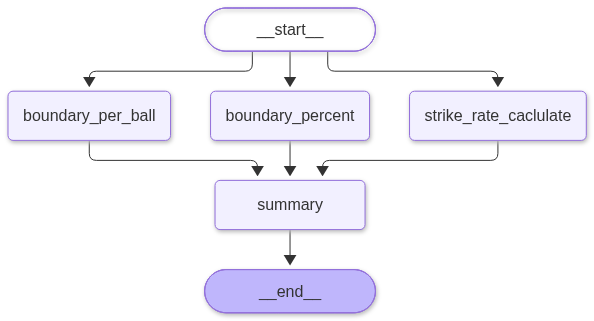

In [11]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())